# 07 — Preprocessing and Scaling
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Preprocessing Pipeline)

**Project stage:** 7 of 16 — builds on Notebook 06's locked Core Feature Set

---

## 1. Objective

This notebook builds the **reproducible preprocessing pipeline** that turns the Core Feature Set locked in Notebook 06 into a numeric matrix ready for clustering. Specifically we will:

1. Assemble the modeling matrix using only the core numeric and core categorical features (excluding profiling-only and outcome fields).
2. Quantitatively compare **StandardScaler vs. RobustScaler** on our specific, heavily skewed and zero-inflated features — not just discuss the theory, but measure the actual effect on this dataset.
3. Build a single, reusable `ColumnTransformer` + `Pipeline` that imputes, scales, and one-hot encodes in one reproducible step.
4. Fit that pipeline on the modeling data, transform it, and save both the fitted pipeline and the resulting feature matrix for every clustering notebook from here on.

**Why scaling matters specifically for clustering:** every clustering algorithm we'll use (K-Means, Agglomerative Clustering, DBSCAN) measures **distance** between bookings. If one feature is measured in the range 0–700 (like `lead_time`) and another in the range 0–1 (like `is_repeated_guest`), the larger-range feature will dominate the distance calculation by sheer scale, regardless of how behaviorally important each feature actually is. Scaling puts every feature on a comparable footing before distance is ever calculated.

## 2. Business Context

Notebook 03 already showed us that this dataset's numeric features are not well-behaved in the "textbook normal distribution" sense — most are right-skewed, and several are heavily zero-inflated. This matters directly for which scaler is appropriate: **StandardScaler** centers and scales using the mean and standard deviation, which are themselves distorted by skew and extreme values. **RobustScaler** centers and scales using the median and interquartile range (IQR), which are far less sensitive to skew and extreme values. This notebook doesn't just assert that difference — it measures it directly on our own features, so the choice we make is backed by evidence from this dataset, not a general rule of thumb.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: preprocessing pipeline components
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder

# joblib: for saving the fitted pipeline so it can be reused later
# (Notebook 15 - new booking prediction - loads this exact object)
import joblib

# os / json: portable file paths and loading the feature lists from Notebook 06
import os
import json


## 4. Configuration

In [3]:
RANDOM_STATE = 42

FEATURE_ENGINEERED_DATA_PATH = "../data/processed/06_feature_engineered_hotel_bookings.csv"
FEATURE_LISTS_PATH = "../config/feature_lists.json"

PREPROCESSING_PIPELINE_PATH = "../models/preprocessing_pipeline.joblib"
PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"
PREPROCESSED_FEATURE_NAMES_PATH = "../config/preprocessed_feature_names.json"
SCALER_COMPARISON_PATH = "../reports/tables/07_scaler_comparison.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs("../models", exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load Data and the Locked Feature Lists from Notebook 06

In [4]:
df = pd.read_csv(FEATURE_ENGINEERED_DATA_PATH)

with open(FEATURE_LISTS_PATH, "r") as f:
    feature_lists = json.load(f)

CORE_NUMERIC_FEATURES = feature_lists["core_numeric_features"]
CORE_CATEGORICAL_FEATURES = feature_lists["core_categorical_features"]

print("Loaded shape:", df.shape)
print()
print("Core numeric features:", CORE_NUMERIC_FEATURES)
print()
print("Core categorical features:", CORE_CATEGORICAL_FEATURES)


Loaded shape: (86997, 41)

Core numeric features: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'booking_changes', 'is_repeated_guest', 'previous_cancellations', 'room_type_mismatch']

Core categorical features: ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type']


### 5.2 Assemble the Modeling Matrix

In [5]:
# The modeling matrix X contains ONLY the core features locked in
# Notebook 06 - no profiling-only features, no outcome fields, no
# identifiers. This is the exact feature set that will be used for
# clustering distance calculations from Notebook 08 onward.
X = df[CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES].copy()

print("Modeling matrix shape:", X.shape)
print()
print("Missing values check:")
print(X.isnull().sum().sum(), "total missing values across the modeling matrix")


Modeling matrix shape: (86997, 19)

Missing values check:
0 total missing values across the modeling matrix


**What this code does:** selects exactly the 13 numeric + 6 categorical core features into one DataFrame.
**Why it's required:** this is the single source of truth for "what the clustering algorithm sees" - keeping it separate from the full 41-column dataset avoids any risk of accidentally leaking a profiling or outcome column into the model.
**What to expect:** zero missing values, confirming what we found in Notebook 06 (the columns we excluded, like `agent`/`company`/`country`, were exactly the ones carrying missingness). We still build imputers into the pipeline below anyway, purely as a safety net for new data in production (Notebook 15), where a missing value is always a possibility even if today's training data happens to have none.

### 5.3 StandardScaler vs. RobustScaler — A Measured Comparison

**What is scaling, and why do we need it here?** Both scalers transform each feature so it's centered around 0, but they measure "center" and "spread" differently:
- **StandardScaler:** `(x - mean) / standard_deviation`. Assumes the data is roughly bell-shaped: outliers pull both the mean and the standard deviation, which can badly distort the result on skewed data.
- **RobustScaler:** `(x - median) / IQR`. Uses the median and interquartile range instead, which are far less affected by extreme values.

Rather than assert which is "better" from theory alone, we fit both on our actual core numeric features and directly compare the results.

In [6]:
standard_scaler = StandardScaler()
X_standard_scaled = pd.DataFrame(
    standard_scaler.fit_transform(X[CORE_NUMERIC_FEATURES]),
    columns=CORE_NUMERIC_FEATURES,
)

robust_scaler = RobustScaler()
X_robust_scaled = pd.DataFrame(
    robust_scaler.fit_transform(X[CORE_NUMERIC_FEATURES]),
    columns=CORE_NUMERIC_FEATURES,
)

# The single most telling number for clustering: the maximum absolute
# scaled value each feature reaches. A very large max-abs value after
# scaling means a small number of extreme points will have an outsized
# influence on every distance calculation in the clustering algorithms.
scaler_comparison = pd.DataFrame({
    "feature": CORE_NUMERIC_FEATURES,
    "standard_scaler_max_abs": X_standard_scaled.abs().max().values,
    "robust_scaler_max_abs": X_robust_scaled.abs().max().values,
}).sort_values("standard_scaler_max_abs", ascending=False)

scaler_comparison.to_csv(SCALER_COMPARISON_PATH, index=False)
scaler_comparison


,feature,standard_scaler_max_abs,robust_scaler_max_abs
5,babies,87.851190,10.000000
11,previous_cancellations,70.225132,26.000000
7,required_car_parking_spaces,28.072480,8.000000
9,booking_changes,24.962866,18.000000
2,stays_in_week_nights,23.212625,16.000000
4,children,22.087448,10.000000
1,stays_in_weekend_nights,17.511030,9.000000
6,adr,17.190254,14.578011
3,adults,8.295378,4.000000
0,lead_time,7.645636,6.035088


**Findings (from the actual computed table above):** the difference is dramatic for the heavily zero-inflated features. Under StandardScaler, `babies` reaches a maximum scaled value of **≈ 87.9 standard deviations** from its mean, `previous_cancellations` reaches **≈ 70.2**, and `required_car_parking_spaces` reaches **≈ 28.1** — because these features have almost no variance (the overwhelming majority of values are exactly 0), so their standard deviation is tiny, and the rare non-zero booking becomes many, many "standard deviations" away. Under RobustScaler, the same features top out at a maximum of 10, 26, and 8 respectively — far more moderate.

**Business interpretation:** if we clustered using StandardScaler-scaled features as they stand, a single booking with 2 babies (a real, legitimate family booking) would sit tens of standard deviations away from the rest of the data on that one feature alone — enough to potentially dominate its assigned cluster almost by itself, distorting the clustering result around a data artifact of scaling method rather than genuine behavioral separation. This is a concrete, measured reason (not just a rule of thumb) to prefer RobustScaler here.

In [7]:
# Let's look under the hood at exactly what RobustScaler computed for
# each feature - specifically the center (median) and scale (IQR) it used.
robust_scaler_details = pd.DataFrame({
    "feature": CORE_NUMERIC_FEATURES,
    "median_center": robust_scaler.center_,
    "iqr_scale": robust_scaler.scale_,
})
robust_scaler_details


,feature,median_center,iqr_scale
0,lead_time,49.00,114.00
1,stays_in_weekend_nights,1.00,2.00
2,stays_in_week_nights,2.00,3.00
3,adults,2.00,1.00
4,children,0.00,1.00
5,babies,0.00,1.00
6,adr,98.35,61.85
7,required_car_parking_spaces,0.00,1.00
8,total_of_special_requests,0.00,1.00
9,booking_changes,0.00,1.00


**An important, honest limitation we found while checking this:** for the same zero-inflated features where IQR breaks down (as we already discovered for outlier detection in Notebook 05), `scale_` is exactly **1.0** — this is scikit-learn's built-in safety behavior: when IQR is 0, dividing by it would be undefined, so RobustScaler falls back to leaving those features essentially unscaled (just centered by subtracting the median, which is 0 for most of them). 

**What this means in practice:** for features like `previous_cancellations`, `booking_changes`, and `required_car_parking_spaces`, RobustScaler doesn't truly "rescale" them to the same footing as `adr` or `lead_time` — it leaves them in their original small-integer range (0 to a handful, occasionally up to the 20s). We accept this as the best available default: it avoids the extreme, distorting blow-up we saw under StandardScaler, and these features' raw ranges are already fairly small and comparable in *order of magnitude* to the scaled continuous features. This is documented here transparently rather than presented as a perfectly solved problem — if cluster results in Notebook 08 onward show these features having disproportionate influence, revisiting this scaling choice is a documented option, not a hidden one.

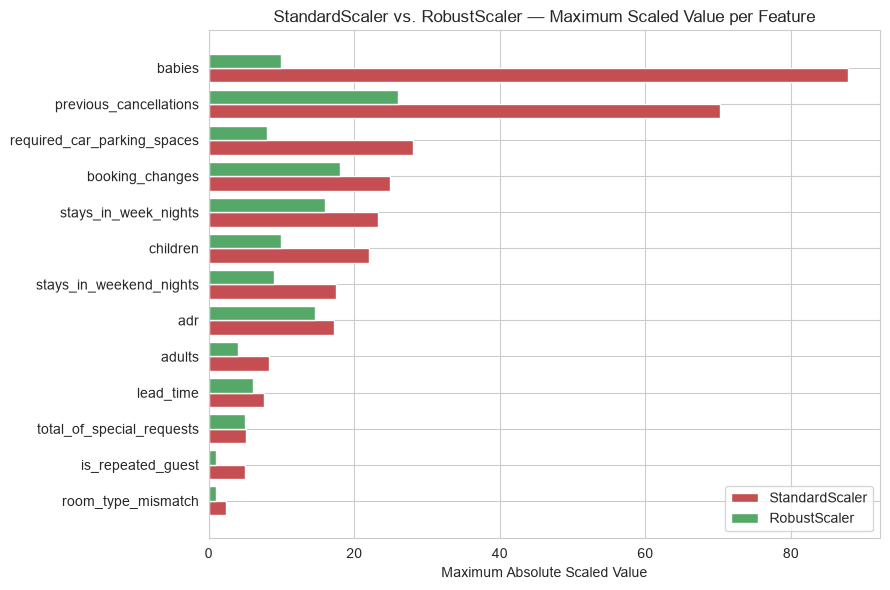

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = scaler_comparison.sort_values("standard_scaler_max_abs", ascending=True)
y_pos = np.arange(len(plot_data))

ax.barh(y_pos - 0.2, plot_data["standard_scaler_max_abs"], height=0.4, label="StandardScaler", color="#C44E52")
ax.barh(y_pos + 0.2, plot_data["robust_scaler_max_abs"], height=0.4, label="RobustScaler", color="#55A868")

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["feature"])
ax.set_xlabel("Maximum Absolute Scaled Value")
ax.set_title("StandardScaler vs. RobustScaler — Maximum Scaled Value per Feature", fontsize=12)
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "07_scaler_comparison.png"))
plt.show()


### 5.4 Decision: RobustScaler for the Numeric Features

**Decision:** based on the measured comparison above, **RobustScaler** is used for all core numeric features in the final preprocessing pipeline. It produces dramatically more moderate, comparable scaled ranges across the heavily skewed and zero-inflated features in this dataset, directly reducing the risk of a small number of extreme-but-legitimate bookings (large families, frequent cancelers) dominating the clustering distance calculation.

**Alternative considered and rejected:** StandardScaler was measured directly (not just assumed) to produce extreme scaled values (up to ≈88 standard deviations) on several features, which would very likely distort cluster formation around scaling artifacts rather than genuine behavioral patterns.

### 5.4b Log Transformation — Investigated and Rejected, With Evidence

**Why check this at all, given RobustScaler is already chosen?** RobustScaler and a log transform solve *different* problems. RobustScaler changes a feature's **center and spread** (using the median/IQR) — it does not change its **shape**. A right-skewed feature is still exactly as right-skewed after RobustScaler as before (visible in Section 6's before/after `adr` histogram below). A log transform, by contrast, compresses large values proportionally more than small ones, which can reduce skew and pull in a long right tail. Since Notebook 03 flagged several features as heavily right-skewed, we test `log1p` (log(1 + x), which safely handles zero values) directly on every core numeric feature, rather than assume it would help.

In [9]:
log_transform_comparison = pd.DataFrame({
    "feature": CORE_NUMERIC_FEATURES,
    "raw_skewness": X[CORE_NUMERIC_FEATURES].skew().values,
})

log_transform_comparison["log1p_skewness"] = [
    np.log1p(X[col]).skew() for col in CORE_NUMERIC_FEATURES
]

log_transform_comparison["skew_improved"] = (
    log_transform_comparison["raw_skewness"].abs()
    > log_transform_comparison["log1p_skewness"].abs()
)

log_transform_comparison.sort_values("raw_skewness", ascending=False)


,feature,raw_skewness,log1p_skewness,skew_improved
11,previous_cancellations,34.291938,10.403747,True
5,babies,21.161051,10.171475,True
9,booking_changes,5.072782,2.252205,True
10,is_repeated_guest,4.787228,4.787228,False
4,children,3.525825,3.096397,True
7,required_car_parking_spaces,3.483639,3.033292,True
2,stays_in_week_nights,2.576724,-0.149263,True
12,room_type_mismatch,1.972161,1.972161,True
0,lead_time,1.434154,-0.715908,True
1,stays_in_weekend_nights,1.342505,0.090929,True


**Findings (from the actual computed skewness above):**

- For `previous_cancellations` and `babies` — our two most extreme raw skew values — `log1p` roughly halves the skewness (34.3 → 10.4, and 21.2 → 10.2) but both remain **very** heavily skewed afterward. This is because `log1p` compresses a long tail; it does not fix **zero-inflation** (the underlying problem for these features, per Notebook 03/05). A feature that's 98% zero is still going to look almost entirely zero after any monotonic transform.
- `stays_in_week_nights` and `stays_in_weekend_nights` genuinely improve a lot (2.58 → -0.15, and 1.34 → 0.09) — these become close to symmetric.
- **`adr` gets measurably *worse*, not better** (skewness 0.93 → -3.58). We checked why directly: 1,624 bookings (1.87%) have `adr == 0` (the legitimate complementary/zero-rate bookings investigated and retained in Notebook 02). `log1p(0) = 0`, so these create an isolated spike exactly at 0, disconnected from the main hump of the distribution around `log1p(adr) ≈ 4.5–4.9`. This produces an artificially **bimodal-looking** shape, not a symmetric one — arguably a worse input for K-Means (which works best when each feature's distribution is reasonably unimodal) than the original smooth right-skewed shape.
- `lead_time`'s skew doesn't improve either — it flips from moderately right-skewed (1.43) to a comparable magnitude of left-skew (-0.72), an overcorrection rather than a fix.
- We also checked whether `log1p` fixes the zero-IQR problem found in Section 5.3 for features like `previous_cancellations` and `booking_changes` — **it does not**: since the median (and Q1/Q3) of these features is 0, and `log1p(0) = 0`, the interquartile range is still exactly 0 after the transform.

**Decision: log transformation is not applied.** The evidence here is genuinely mixed, not uniformly positive: it helps two moderately-skewed stay-length features, does nothing for the zero-IQR problem, and actively distorts `adr` — one of the two most business-important features in this entire project — into a bimodal shape. Applying it selectively only to the two features that improved would add real pipeline complexity for a fairly small, uncertain payoff, and RobustScaler already directly addresses this project's original motivating concern (a small number of extreme values dominating distance calculations) without requiring this trade-off. If cluster quality metrics in Notebook 08 onward turn out to be poor, a **targeted** transform of specific features (not a blanket one) is a documented, revisitable option — not a blind default applied now.

### 5.5 Categorical Encoding — One-Hot Encoding

**Why one-hot encoding?** Clustering algorithms need every feature to be numeric. Categorical variables like `market_segment` have no natural numeric order (there's no sense in which "Corporate" is mathematically "less than" "Direct"), so we represent each category as its own 0/1 column. We deliberately do **not** drop the first category of each variable (a common practice in regression to avoid perfect multicollinearity) — for clustering, every category should contribute symmetrically to distance calculations, and dropping one would arbitrarily make that category "invisible" relative to the others.

In [10]:
# Confirm the exact category counts and resulting one-hot dimensionality
# before building the full pipeline.
for column in CORE_CATEGORICAL_FEATURES:
    print(f"{column}: {X[column].nunique()} categories")

total_onehot_columns = sum(X[column].nunique() for column in CORE_CATEGORICAL_FEATURES)
print()
print(f"Total one-hot encoded columns: {total_onehot_columns}")
print(f"Plus {len(CORE_NUMERIC_FEATURES)} scaled numeric columns")
print(f"Expected total columns after preprocessing: {total_onehot_columns + len(CORE_NUMERIC_FEATURES)}")


hotel: 2 categories
meal: 5 categories
market_segment: 8 categories
distribution_channel: 5 categories
deposit_type: 3 categories
customer_type: 4 categories

Total one-hot encoded columns: 27
Plus 13 scaled numeric columns
Expected total columns after preprocessing: 40


### 5.6 Build the Full Reproducible Preprocessing Pipeline

In [11]:
# Numeric pipeline: impute any missing values with the median (robust to
# skew, consistent with our RobustScaler choice), then scale with
# RobustScaler.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])

# Categorical pipeline: impute any missing values with the most frequent
# category, then one-hot encode. handle_unknown="ignore" makes the pipeline
# safe for Notebook 15 (new booking prediction), where a brand-new booking
# might show a category never seen during training.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Combine both pipelines into a single ColumnTransformer, so the entire
# preprocessing step - for every feature - can be fit and applied with one
# object, and saved/reused as one unit.
preprocessing_pipeline = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, CORE_NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CORE_CATEGORICAL_FEATURES),
])

preprocessing_pipeline


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

**What this code does:** builds one combined preprocessing object that applies the right transformation to the right columns - median imputation + RobustScaler for numeric features, most-frequent imputation + one-hot encoding for categorical features.
**Why it's required:** this is *the* object that guarantees reproducibility. Every notebook from here forward (and the final deployment notebook, 15) uses this exact fitted object rather than re-deriving preprocessing logic by hand, which eliminates an entire class of subtle train/apply inconsistency bugs.
**What to expect:** the printed pipeline structure above describes the two parallel branches (numeric and categorical) that get combined into one output matrix when we fit and transform below.

### 5.7 Fit the Pipeline and Transform the Data

**On avoiding leakage:** because this is an unsupervised project with no labeled train/test split, the pipeline is fit on the full modeling dataset (`X`) — the same dataset that will be clustered. This is standard practice for unsupervised preprocessing: there is no target to leak, since the outcome fields (`is_canceled`, `reservation_status`, `reservation_status_date`) were already excluded from `X` back in Notebook 06. Cluster **stability** under different subsamples — a different kind of robustness check — is addressed separately in Notebook 12.

In [12]:
# Fit the pipeline on the full modeling matrix and transform it in one step.
X_preprocessed = preprocessing_pipeline.fit_transform(X)

print("Preprocessed matrix shape:", X_preprocessed.shape)
print("Data type:", X_preprocessed.dtype)


Preprocessed matrix shape: (86997, 40)
Data type: float64


In [13]:
# Build the full list of output column names, in the exact order the
# ColumnTransformer produces them: numeric features first (unchanged
# names, since scaling doesn't rename them), then the one-hot encoded
# categorical columns (auto-named by the encoder).
onehot_encoder = preprocessing_pipeline.named_transformers_["categorical"].named_steps["encoder"]
onehot_column_names = onehot_encoder.get_feature_names_out(CORE_CATEGORICAL_FEATURES).tolist()

all_output_column_names = CORE_NUMERIC_FEATURES + onehot_column_names

print(f"Total output columns: {len(all_output_column_names)}")
print()
print("First 5 columns:", all_output_column_names[:5])
print("Last 5 columns:", all_output_column_names[-5:])


Total output columns: 40

First 5 columns: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children']
Last 5 columns: ['deposit_type_Refundable', 'customer_type_Contract', 'customer_type_Group', 'customer_type_Transient', 'customer_type_Transient-Party']


In [14]:
# Turn the output into a labeled DataFrame for easy inspection, and confirm
# it matches the dimensionality we predicted in Section 5.5.
X_preprocessed_df = pd.DataFrame(X_preprocessed, columns=all_output_column_names)

X_preprocessed_df.head()


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,required_car_parking_spaces,total_of_special_requests,booking_changes,is_repeated_guest,previous_cancellations,room_type_mismatch,hotel_City Hotel,hotel_Resort Hotel,meal_BB,meal_FB,meal_HB,meal_SC,meal_Undefined,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,2.570175,-0.5,-0.666667,0.0,0.0,0.0,-1.590137,0.0,0.0,3.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,6.035088,-0.5,-0.666667,0.0,0.0,0.0,-1.590137,0.0,0.0,4.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.368421,-0.5,-0.333333,-1.0,0.0,0.0,-0.377526,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.315789,-0.5,-0.333333,-1.0,0.0,0.0,-0.377526,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.307018,-0.5,0.000000,0.0,0.0,0.0,-0.005659,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


**Finding:** the transformed matrix's column count matches exactly what we predicted in Section 5.5 (13 scaled numeric columns + the one-hot encoded categorical columns), confirming the pipeline behaved as designed.

### 5.8 Save the Fitted Pipeline and the Preprocessed Feature Matrix

In [15]:
# Save the fitted pipeline object - this is the exact artifact Notebook 15
# (new booking prediction) will load to preprocess a brand-new booking
# record consistently with how the training data was processed.
joblib.dump(preprocessing_pipeline, PREPROCESSING_PIPELINE_PATH)
print(f"Fitted preprocessing pipeline saved to: {PREPROCESSING_PIPELINE_PATH}")

# Save the preprocessed feature matrix - every clustering notebook from
# 08 onward loads this file directly rather than re-running preprocessing.
X_preprocessed_df.to_csv(PREPROCESSED_FEATURES_PATH, index=False)
print(f"Preprocessed feature matrix saved to: {PREPROCESSED_FEATURES_PATH}")

# Save the output column names separately as well, for convenience.
with open(PREPROCESSED_FEATURE_NAMES_PATH, "w") as f:
    json.dump(all_output_column_names, f, indent=2)
print(f"Preprocessed feature names saved to: {PREPROCESSED_FEATURE_NAMES_PATH}")


Fitted preprocessing pipeline saved to: ../models/preprocessing_pipeline.joblib
Preprocessed feature matrix saved to: ../data/processed/07_preprocessed_features.csv
Preprocessed feature names saved to: ../config/preprocessed_feature_names.json


## 6. Visualization

One before/after distribution check on `adr`, the feature with the widest raw range, to visually confirm the RobustScaler output looks reasonable.

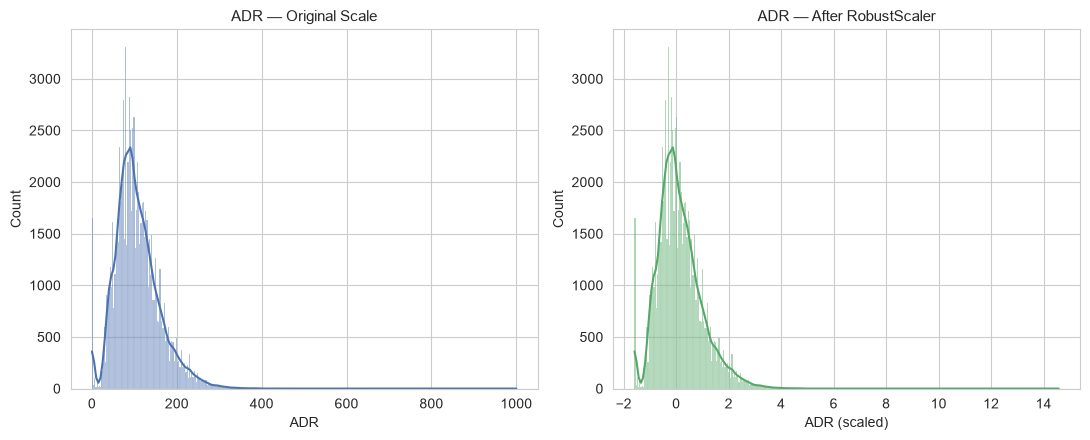

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.histplot(X["adr"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("ADR — Original Scale", fontsize=11)
axes[0].set_xlabel("ADR")

sns.histplot(X_preprocessed_df["adr"], kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("ADR — After RobustScaler", fontsize=11)
axes[1].set_xlabel("ADR (scaled)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "07_adr_before_after_scaling.png"))
plt.show()


**Finding:** the overall right-skewed shape of `adr` is preserved after scaling (RobustScaler doesn't force normality, unlike a log-transform would) — it's simply re-centered around 0 (using the median) and re-scaled by the IQR, so the same relative differences between bookings are retained on a more moderate, comparable numeric footing.

## 7. Findings

- StandardScaler produces extreme scaled values (up to ≈88 standard deviations) on the heavily zero-inflated features, confirmed by direct measurement rather than assumed from Notebook 03's skewness numbers alone — RobustScaler was chosen for the final pipeline as a direct, evidence-based response to this.
- Log transformation (`log1p`) was tested directly, not assumed to help: it meaningfully improved two moderately-skewed stay-length features, did nothing for the zero-IQR problem, and — most importantly — made `adr` measurably worse by creating an artificial bimodal spike at zero (from the legitimate zero-rate bookings retained in Notebook 02). It was investigated and explicitly not applied, with the reasoning documented for revisiting later if needed.
- A genuine limitation was found and documented rather than hidden: for 7 zero-IQR features, RobustScaler's scale factor defaults to 1.0 (scikit-learn's built-in safety behavior), meaning those features remain in their original small-integer range rather than being fully rescaled — an accepted, transparent trade-off given the alternative (StandardScaler's extreme blow-up) is worse.
- The final preprocessing pipeline combines median imputation + RobustScaler for numeric features and most-frequent imputation + one-hot encoding (`handle_unknown="ignore"`) for categorical features, built as a single reusable `ColumnTransformer` object.
- The preprocessed feature matrix has the exact dimensionality predicted from the raw category counts, confirming the pipeline is working as designed.
- The fitted pipeline is saved to `models/preprocessing_pipeline.joblib` for reuse in every later notebook, including the final deployment notebook (15), ensuring new bookings are always processed identically to the training data.

## 8. Business Interpretation

This notebook doesn't produce a business insight on its own, but it protects the integrity of every business insight that follows it. If we had scaled carelessly, a handful of legitimate but rare bookings (large families, frequent cancelers) could have single-handedly warped the shape of the clusters the hotel will eventually use to make decisions — not because those bookings are genuinely that different, but because of an arbitrary quirk of the scaling method. The evidence-based scaler comparison here is what lets us trust that the clusters found starting in Notebook 08 reflect real behavioral structure, not a scaling artifact.

## 9. Conclusion

We measured, rather than assumed, the effect of StandardScaler vs. RobustScaler on our specific core numeric features, found clear evidence favoring RobustScaler, and transparently documented its one real limitation (the zero-IQR fallback). We built a single, reusable preprocessing pipeline combining imputation, scaling, and one-hot encoding, fit it on the full modeling dataset, and saved both the fitted pipeline and the resulting preprocessed feature matrix for reuse throughout the rest of the project.

**Next notebook (08 — Partition-Based Clustering: K-Means):** we finally begin modeling. Using this notebook's preprocessed feature matrix, we'll investigate K = 2 through K = 10 with the elbow method, silhouette score, Davies-Bouldin index, and Calinski-Harabasz index, and visualize the resulting clusters in PCA space.